In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1


# Modeling

## 1. Modeling Overview

در این مرحله از متدولوژی CRISP-DM، با استفاده از دیتاست آماده‌شده در مرحله Data Preparation، الگوریتم‌های یادگیری ماشین را پیاده‌سازی و ارزیابی می‌کنیم.

هدف این پروژه در دو بخش دنبال می‌شود:

### 1. Clustering

در این بخش با استفاده از الگوریتم‌های خوشه‌بندی، مشتریان را بر اساس ویژگی‌های رفتاری مانند Recency، Frequency و Monetary گروه‌بندی می‌کنیم.

هدف، شناسایی الگوهای مختلف رفتاری مشتریان و بررسی گروه‌هایی است که نشانه‌های بیشتری از ریسک ریزش دارند.

### 2. Classification

در این بخش از الگوریتم‌های طبقه‌بندی برای پیش‌بینی احتمال ریزش مشتریان استفاده می‌کنیم.

متغیر هدف `Churn` است که در مرحله Data Preparation بر اساس قانون ۹۰ روز بدون خرید معتبر ایجاد شده است.

در نهایت، مشتریان بر اساس احتمال ریزش رتبه‌بندی می‌شوند تا ۵۰۰ مشتری با بالاترین ریسک انتخاب شوند.

معیار اصلی ارزیابی تجاری پروژه، Precision@500 خواهد بود.


In [2]:
from pathlib import Path

file_path = Path(
    "../03_Data Prepeation/prepared_data/customer_churn_dataset.csv"
)
if not file_path.exists():
    raise FileNotFoundError("Dataset not found!")

df_model = pd.read_csv(file_path)

print("Dataset loaded successfully!")

print("Dataset Shape:", df_model.shape)

display(df_model.head())

Dataset loaded successfully!
Dataset Shape: (2783, 7)


,CustomerID,Recency,Frequency,Monetary,UniqueProducts,TenureDays,Churn
0,12347,39,3,1603.68,50,117,0
1,12348,158,1,327.00,4,0,0
2,12352,172,2,240.66,7,5,0
3,12353,114,1,89.00,4,0,1
4,12354,142,1,1079.40,58,0,1


## 2. Loading Prepared Dataset

در این مرحله دیتاست آماده‌شده در بخش Data Preparation را وارد محیط Modeling می‌کنیم.

این دیتاست شامل ویژگی‌های رفتاری مشتریان و برچسب ریزش آن‌هاست.

هدف، آماده‌سازی داده‌ها برای اجرای الگوریتم‌های Clustering و Classification است.
_________________________________________________________________________________________________________

In [3]:

df_model.info()

print("\nDataset Shape:", df_model.shape)

print("\nDataset Columns:")
print(df_model.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 2783 entries, 0 to 2782
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      2783 non-null   int64  
 1   Recency         2783 non-null   int64  
 2   Frequency       2783 non-null   int64  
 3   Monetary        2783 non-null   float64
 4   UniqueProducts  2783 non-null   int64  
 5   TenureDays      2783 non-null   int64  
 6   Churn           2783 non-null   int64  
dtypes: float64(1), int64(6)
memory usage: 152.3 KB

Dataset Shape: (2783, 7)

Dataset Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'TenureDays', 'Churn']


بررسی اطلاعات دیتاست
## 3. Dataset Inspection

در این مرحله کیفیت و ساختار دیتاست آماده‌شده را بررسی می‌کنیم.

هدف، اطمینان از نبود مقادیر گمشده، رکوردهای تکراری و برچسب‌های نامعتبر است.

همچنین توزیع متغیر هدف Churn بررسی می‌شود تا نسبت مشتریان ریزش‌کرده و غیرریزشی مشخص شود.

این بررسی‌ها پیش از ورود به الگوریتم‌های یادگیری ماشین انجام می‌شوند.


In [4]:

print("Missing Values:")
display(df_model.isna().sum())



print("\nDuplicate CustomerIDs:")

print(df_model["CustomerID"].duplicated().sum())


print("\nValid Churn Labels:")

print(df_model["Churn"].value_counts())

Missing Values:


CustomerID        0
Recency           0
Frequency         0
Monetary          0
UniqueProducts    0
TenureDays        0
Churn             0
dtype: int64


Duplicate CustomerIDs:
0

Valid Churn Labels:
Churn
0    1719
1    1064
Name: count, dtype: int64


بررسی داده‌های گمشده و تکراری

In [5]:

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "TenureDays"
]


customer_ids = df_model["CustomerID"].copy()


X = df_model[feature_columns].copy()


y = df_model["Churn"].copy()


X_cluster = X.copy()


print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("Clustering Shape:", X_cluster.shape)

Features Shape: (2783, 5)
Target Shape: (2783,)
Clustering Shape: (2783, 5)


تفکیک Feature و Target

این قسمت بسیار مهم است.

ابتدا تفاوت این دو مفهوم را بدانیم:

Feature (X): اطلاعاتی که مدل برای یادگیری و پیش‌بینی استفاده می‌کند.

Target (y): چیزی که مدل قرار است پیش‌بینی کند.

در پروژه ما:

Features عبارت‌اند از:

Recency
Frequency
Monetary
UniqueProducts
TenureDays

Target:

Churn

## 4. Feature and Target Separation

در این مرحله ویژگی‌های ورودی و متغیر هدف از یکدیگر تفکیک می‌شوند.

ویژگی‌های ورودی شامل Recency، Frequency، Monetary، UniqueProducts و TenureDays هستند.

متغیر Churn به‌عنوان Target برای مسئله Classification در نظر گرفته می‌شود.

همچنین CustomerID به‌صورت مستقل نگهداری می‌شود؛ زیرا صرفاً شناسه مشتری است و نباید در محاسبات الگوریتم‌ها وارد شود.

برای Clustering فقط ویژگی‌های رفتاری استفاده می‌شوند و ستون Churn در اختیار الگوریتم قرار نمی‌گیرد.

در نتیجه دو مجموعه داده آماده می‌شود:

* X_cluster برای Clustering
* X و y برای Classification
_________________________________________________________________________________________________________

In [6]:

skewness = X_cluster.skew()

print("Feature Skewness:")

display(
    skewness.sort_values(ascending=False).to_frame("Skewness")
)

Feature Skewness:


,Skewness
Monetary,15.180525
Frequency,8.533705
UniqueProducts,6.615032
TenureDays,0.645414
Recency,0.573766


بررسی چولگی ویژگی‌ها

In [7]:

log_features = [
    "Frequency",
    "Monetary",
    "UniqueProducts"
]



X_cluster_transformed = X_cluster.copy()


X_cluster_transformed[log_features] = np.log1p(
    X_cluster_transformed[log_features]
)


display(X_cluster_transformed.head())

,Recency,Frequency,Monetary,UniqueProducts,TenureDays
0,39,1.386294,7.380680,3.931826,117
1,158,0.693147,5.793014,1.609438,0
2,172,1.098612,5.487532,2.079442,5
3,114,0.693147,4.499810,1.609438,0
4,142,0.693147,6.985087,4.077537,0


تبدیل لگاریتمی (Log Transformation)
مفهوم چیست؟

تبدیل لگاریتمی باعث می‌شود فاصله بین مقادیر بسیار بزرگ کمتر شود.

مثلاً اختلاف بین ۱۰۰ و ۱۰۰۰ بعد از تبدیل لگاریتمی، نسبت به مقیاس اولیه کوچک‌تر می‌شود.

برای این کار از np.log1p() استفاده می‌کنیم.

In [8]:

from sklearn.preprocessing import StandardScaler


scaler_cluster = StandardScaler()


X_cluster_scaled_array = scaler_cluster.fit_transform(
    X_cluster_transformed
)


X_cluster_scaled = pd.DataFrame(
    X_cluster_scaled_array,
    columns=X_cluster_transformed.columns,
    index=X_cluster_transformed.index
)


display(X_cluster_scaled.head())

,Recency,Frequency,Monetary,UniqueProducts,TenureDays
0,-0.526357,0.439423,0.943233,0.628246,1.103719
1,1.771615,-0.818137,-0.435500,-1.615665,-0.870653
2,2.041965,-0.082511,-0.700781,-1.161544,-0.786278
3,0.921945,-0.818137,-1.558522,-1.615665,-0.870653
4,1.462644,-0.818137,0.599699,0.769034,-0.870653


استانداردسازی با StandardScaler

حالا که چولگی ویژگی‌ها را کاهش دادیم، می‌توانیم استانداردسازی را انجام دهیم.

In [9]:

print("Mean After Scaling:")

display(X_cluster_scaled.mean().round(3))


print("\nStandard Deviation After Scaling:")

display(
    X_cluster_scaled.std(ddof=0).round(3)
)

Mean After Scaling:


Recency          -0.0
Frequency        -0.0
Monetary          0.0
UniqueProducts   -0.0
TenureDays       -0.0
dtype: float64


Standard Deviation After Scaling:


Recency           1.0
Frequency         1.0
Monetary          1.0
UniqueProducts    1.0
TenureDays        1.0
dtype: float64

بررسی نتیجه استانداردسازی

حالا می‌خواهیم مطمئن شویم Standardization درست انجام شده است.

## 5. Log Transformation and Standardization

در این مرحله ویژگی‌های رفتاری مشتریان را برای اجرای الگوریتم K-Means آماده می‌کنیم.

بر اساس نتایج Data Understanding، ویژگی‌های Frequency، Monetary و UniqueProducts دارای چولگی مثبت قابل توجه بودند.

به همین دلیل ابتدا با استفاده از تابع `np.log1p()` تبدیل لگاریتمی روی این ویژگی‌ها اعمال شد تا تأثیر مقادیر بسیار بزرگ کاهش یابد.

سپس با استفاده از ابزار `StandardScaler` از کتابخانه Scikit-learn، تمام ویژگی‌های رفتاری استانداردسازی شدند.

هدف از استانداردسازی، قرار دادن ویژگی‌ها در مقیاسی مشترک با میانگین صفر و انحراف معیار یک است.

این کار اهمیت زیادی دارد؛ زیرا الگوریتم K-Means بر اساس فاصله بین نمونه‌ها عمل می‌کند و اختلاف زیاد مقیاس ویژگی‌ها می‌تواند بر تشکیل خوشه‌ها تأثیر بگذارد.

در این مرحله ستون‌های CustomerID و Churn وارد فرایند تبدیل و استانداردسازی نشده‌اند.

خروجی نهایی در دیتافریم `X_cluster_scaled` ذخیره می‌شود و در مرحله بعد برای اجرای الگوریتم K-Means مورد استفاده قرار خواهد گرفت.
_________________________________________________________________________________________________________

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

وارد کردن ابزارهای موردنیاز

KMeans:

الگوریتم خوشه‌بندی موردنظر ماست.

silhouette_score:

تابعی برای ارزیابی کیفیت خوشه‌بندی است که کمی جلوتر از آن استفاده می‌کنیم.

In [11]:

k_values = range(2, 11)

inertia_values = []
silhouette_values = []


for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    cluster_labels = kmeans.fit_predict(
        X_cluster_scaled
    )

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_cluster_scaled,
            cluster_labels
        )
    )


cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette": silhouette_values
})


display(cluster_evaluation.round(4))

,K,Inertia,Silhouette
0,2,7198.8359,0.4123
1,3,5761.8083,0.2861
2,4,4809.1861,0.2729
3,5,4200.6804,0.2609
4,6,3801.0240,0.2416
5,7,3431.5493,0.2480
6,8,3186.5052,0.2381
7,9,3015.8224,0.2348
8,10,2848.6835,0.2245


محاسبه Inertia برای Kهای مختلف

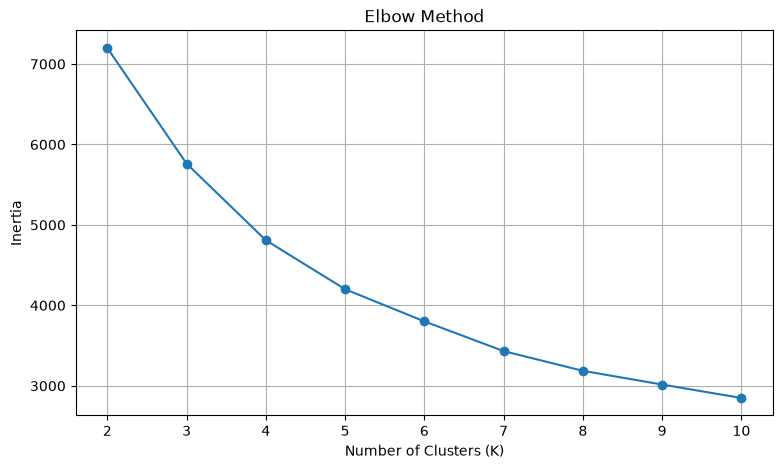

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.xticks(list(k_values))

plt.grid(True)

plt.show()

رسم نمودار Elbow

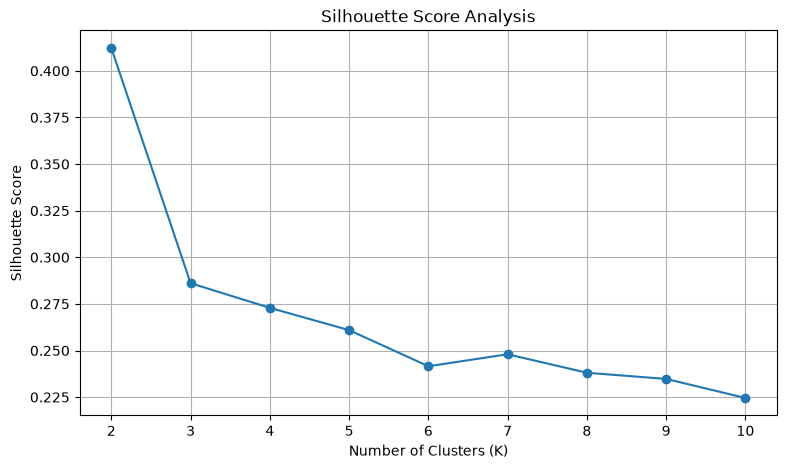

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Silhouette"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Silhouette Score")

plt.title("Silhouette Score Analysis")

plt.xticks(list(k_values))

plt.grid(True)

plt.show()

رسم نمودار Silhouette

در این نمودار:

محور افقی تعداد خوشه‌هاست.
محور عمودی امتیاز Silhouette است.

دنبال Kهایی می‌گردیم که امتیاز بالاتری دارند.

## 6. Optimal Number of Clusters Selection

در این مرحله تعداد مناسب خوشه‌ها برای الگوریتم K-Means تعیین می‌شود.

از آنجایی که تعداد خوشه‌ها باید قبل از اجرای نهایی الگوریتم مشخص شود، چند مقدار مختلف برای K بررسی می‌شوند.

برای انتخاب تعداد مناسب خوشه‌ها از دو معیار استفاده می‌کنیم:

### 1. Elbow Method

در این روش مقدار Inertia برای تعداد خوشه‌های مختلف محاسبه و رسم می‌شود.

هدف، شناسایی نقطه‌ای است که پس از آن افزایش تعداد خوشه‌ها باعث کاهش قابل‌توجه Inertia نمی‌شود.

### 2. Silhouette Score

این معیار میزان شباهت نمونه‌های داخل هر خوشه و میزان جدایی آن‌ها از خوشه‌های دیگر را بررسی می‌کند.

مقدار آن بین منفی یک و مثبت یک قرار دارد و مقادیر بالاتر معمولاً نشان‌دهنده جداسازی بهتر خوشه‌ها هستند.

در این پروژه هر دو معیار بررسی می‌شوند تا تعداد خوشه‌ها صرفاً بر اساس یک شاخص انتخاب نشود.

در نهایت، علاوه بر نتایج عددی، قابل‌تفسیر بودن خوشه‌ها و معنای تجاری آن‌ها نیز در انتخاب K نهایی در نظر گرفته خواهد شد.
_________________________________________________________________________________________________________

In [15]:

optimal_k = 2

print("Selected K:", optimal_k)

Selected K: 2


تعیین تعداد خوشه‌ها

In [16]:
from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)


cluster_labels = kmeans_model.fit_predict(
    X_cluster_scaled
)


print("K-Means model trained successfully!")

K-Means model trained successfully!


## 7. Final K-Means Clustering

پس از بررسی نمودارهای Elbow و Silhouette، مقدار K=2 به‌عنوان انتخاب اولیه برای اجرای الگوریتم K-Means در نظر گرفته شد.

معیار اصلی این انتخاب، بالاترین مقدار Silhouette Score در بین مقادیر آزمایش‌شده بود.

در این مرحله الگوریتم K-Means با استفاده از ویژگی‌های استانداردشده مشتریان اجرا می‌شود.

هدف، تقسیم مشتریان به دو گروه بر اساس شباهت رفتار خرید آن‌هاست.


In [17]:

df_clustered = df_model[
    ["CustomerID"] + feature_columns
].copy()


df_clustered["Cluster"] = cluster_labels


df_clustered["Churn"] = y.to_numpy()


display(df_clustered.head(10))

,CustomerID,Recency,Frequency,Monetary,UniqueProducts,TenureDays,Cluster,Churn
0,12347,39,3,1603.68,50,117,1,0
1,12348,158,1,327.00,4,0,0,0
2,12352,172,2,240.66,7,5,0,0
3,12353,114,1,89.00,4,0,0,1
4,12354,142,1,1079.40,58,0,0,1
5,12355,124,1,459.40,13,0,0,1
6,12356,155,1,481.46,21,0,0,0
7,12358,60,1,404.86,11,0,0,0
8,12359,99,1,1109.32,47,0,0,0
9,12360,22,2,1378.28,62,88,1,0


اضافه کردن خوشه‌ها به دیتاست

حالا باید نتیجه الگوریتم را به اطلاعات مشتریان اضافه کنیم

In [18]:

cluster_counts = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
)


print("Customers in Each Cluster:")

display(cluster_counts)


cluster_percentage = (
    cluster_counts / len(df_clustered)
) * 100


print("\nCluster Percentages:")

display(cluster_percentage.round(2))

Customers in Each Cluster:


Cluster
0    1659
1    1124
Name: count, dtype: int64


Cluster Percentages:


Cluster
0    59.61
1    40.39
Name: count, dtype: float64

بررسی تعداد مشتریان هر خوشه

In [19]:
from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)


print("Selected K:", optimal_k)

print("Inertia:", round(kmeans_model.inertia_, 2))

print("Silhouette Score:", round(final_silhouette, 4))

Selected K: 2
Inertia: 7198.84
Silhouette Score: 0.4123


ارزیابی خوشه‌بندی نهایی
_________________________________________________________________________________________________________

## 8. Cluster Analysis

پس از اجرای الگوریتم K-Means و اختصاص مشتریان به دو خوشه، در این مرحله رفتار هر خوشه را بررسی می‌کنیم.

هدف این مرحله شناخت ویژگی‌های رفتاری گروه‌های ایجادشده و بررسی تفاوت آن‌ها از نظر Recency، Frequency، Monetary، تنوع محصولات و رفتار ریزش است.

برای تحلیل خوشه‌ها از آمار توصیفی ویژگی‌ها و نرخ ریزش مشتریان در هر خوشه استفاده می‌کنیم.

نکته مهم این است که ستون Churn در اجرای K-Means استفاده نشده و صرفاً پس از تشکیل خوشه‌ها برای بررسی ارتباط گروه‌های رفتاری با ریزش مشتریان مورد استفاده قرار می‌گیرد.

در نهایت، بر اساس ویژگی‌های هر خوشه، تفسیر تجاری مناسبی برای گروه‌های مشتریان ارائه می‌شود.


In [20]:

cluster_counts = (
    df_clustered
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "nunique")
    )
)

cluster_counts["Percentage"] = (
    cluster_counts["Customer_Count"]
    / len(df_clustered)
) * 100

display(cluster_counts.round(2))

,Customer_Count,Percentage
Cluster,,
0,1659,59.61
1,1124,40.39


محاسبه تعداد مشتریان هر خوشه

ابتدا می‌خواهیم بدانیم هر خوشه چند مشتری دارد.

In [21]:

cluster_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "TenureDays"
]

cluster_profile = (
    df_clustered
    .groupby("Cluster")[cluster_features]
    .agg(["mean", "median"])
)

display(cluster_profile.round(2))

Recency        Frequency        Monetary          UniqueProducts  \
           mean median      mean median     mean   median           mean   
Cluster                                                                    
0         90.80   92.0      1.29    1.0   425.05   301.80          21.67   
1         30.04   23.0      5.19    4.0  2558.41  1272.26          74.08   

               TenureDays         
        median       mean median  
Cluster                           
0         17.0       9.92    0.0  
1         55.0     113.11  118.0

بررسی ویژگی‌های هر خوشه

این قسمت مهم‌ترین بخش تحلیل ماست.

می‌خواهیم ببینیم میانگین و میانه ویژگی‌های مشتریان در هر خوشه چقدر است.

In [22]:

cluster_churn = (
    df_clustered
    .groupby("Cluster")
    .agg(
        Total_Customers=("CustomerID", "nunique"),

        Churned_Customers=("Churn", "sum"),

        Churn_Rate=("Churn", "mean")
    )
)


cluster_churn["Churn_Rate"] *= 100


display(cluster_churn.round(2))

,Total_Customers,Churned_Customers,Churn_Rate
Cluster,,,
0,1659,864,52.08
1,1124,200,17.79


بررسی نرخ ریزش در هر خوشه

حالا به یکی از مهم‌ترین سؤالات پروژه می‌رسیم:

آیا نرخ ریزش مشتریان در دو خوشه متفاوت است؟

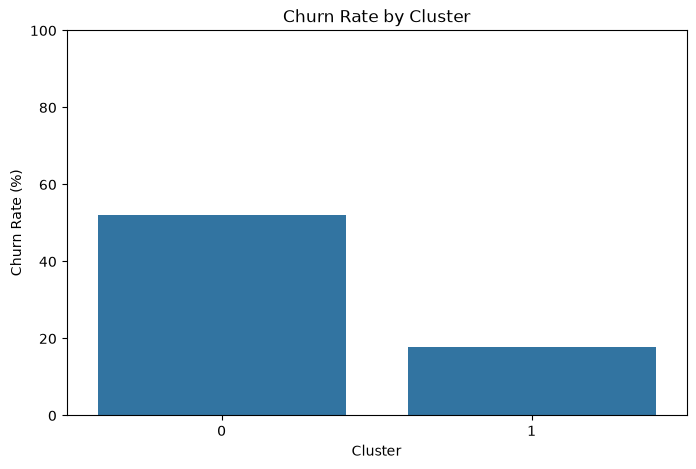

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=cluster_churn.reset_index(),
    x="Cluster",
    y="Churn_Rate"
)

plt.title("Churn Rate by Cluster")

plt.xlabel("Cluster")

plt.ylabel("Churn Rate (%)")

plt.ylim(0, 100)

plt.show()

رسم نمودار نرخ ریزش خوشه‌ها

برای اینکه مقایسه راحت‌تر شود، نرخ ریزش دو خوشه را رسم می‌کنیم.

## 9. Cluster Interpretation

در این مرحله خوشه‌های ایجادشده توسط الگوریتم K-Means از نظر ویژگی‌های رفتاری و نرخ ریزش بررسی می‌شوند.

برای شناخت بهتر هر گروه، ویژگی‌های Recency، Frequency، Monetary، UniqueProducts و TenureDays در سطح خوشه تحلیل می‌شوند.

همچنین نرخ ریزش هر خوشه بر اساس برچسب Churn محاسبه می‌شود.

هدف این تحلیل شناسایی گروه‌هایی است که رفتار خرید متفاوتی دارند و بررسی ارتباط این رفتارها با ریسک ریزش مشتریان است.

بر اساس نتایج به‌دست‌آمده، برای هر خوشه یک تفسیر تجاری ارائه می‌شود.

این تحلیل کمک می‌کند گروه‌های پرخطر مشتریان را بهتر بشناسیم و در مراحل Classification از این شناخت برای ارزیابی نتایج پیش‌بینی استفاده کنیم.
## 9. Final Cluster Analysis and Interpretation

پس از اجرای الگوریتم K-Means با دو خوشه، رفتار مشتریان از نظر ویژگی‌های RFM و سایر ویژگی‌های رفتاری بررسی شد.

### Cluster 0: At-Risk / Low-Engagement Customers

این خوشه شامل 1,659 مشتری، معادل 59.61 درصد کل مشتریان است.

ویژگی‌های اصلی این گروه:

* میانگین Recency برابر 90.80 روز است.
* میانگین Frequency برابر 1.29 است.
* میانگین Monetary برابر 425.05 است.
* میانگین TenureDays برابر 9.92 روز است.

این نتایج نشان می‌دهد مشتریان این خوشه عمدتاً فعالیت خرید محدود و تکرار خرید پایینی دارند.

نرخ ریزش در این خوشه برابر 52.08 درصد است.

### Cluster 1: Active / High-Value Customers

این خوشه شامل 1,124 مشتری، معادل 40.39 درصد کل مشتریان است.

ویژگی‌های اصلی این گروه:

* میانگین Recency برابر 30.04 روز است.
* میانگین Frequency برابر 5.19 است.
* میانگین Monetary برابر 2,558.41 است.
* میانگین TenureDays برابر 113.11 روز است.

این نتایج نشان می‌دهد مشتریان این خوشه فعالیت خرید بیشتر، تکرار خرید بالاتر و ارزش مالی بیشتری دارند.

نرخ ریزش این خوشه برابر 17.79 درصد است.

### Business Findings

مقایسه نرخ ریزش دو خوشه نشان می‌دهد که نرخ ریزش مشتریان Cluster 0 تقریباً 2.9 برابر Cluster 1 است.

همچنین حدود 81.2 درصد مشتریان ریزشی در Cluster 0 قرار دارند.

این موضوع نشان می‌دهد خوشه‌بندی توانسته گروهی از مشتریان با رفتار خرید ضعیف‌تر و ریسک ریزش بالاتر را شناسایی کند.

بنابراین Cluster 0 به‌عنوان گروه دارای اولویت بالاتر برای بررسی و اقدامات حفظ مشتری در نظر گرفته می‌شود.

**نکته:** برچسب Churn در اجرای K-Means استفاده نشده و فقط پس از تشکیل خوشه‌ها برای تحلیل رفتار ریزش مشتریان بررسی شده است.

_________________________________________________________________________________________________________

## 10. Train and Test Split

در این مرحله دیتاست را به دو مجموعه آموزش (Train) و آزمون (Test) تقسیم می‌کنیم.

هدف از این تقسیم‌بندی، آموزش مدل با بخشی از داده‌ها و ارزیابی عملکرد آن با استفاده از داده‌هایی است که مدل قبلاً مشاهده نکرده است.

در این پروژه تقسیم داده‌ها به نسبت 80 درصد آموزش و 20 درصد آزمون انجام می‌شود.

همچنین برای حفظ نسبت مشتریان ریزش‌کرده و غیرریزش‌کرده در هر دو مجموعه، از روش Stratified Sampling استفاده می‌کنیم.

با این روش توزیع کلاس‌های Churn در مجموعه‌های Train و Test تقریباً مشابه دیتاست اصلی باقی می‌ماند.

این تقسیم‌بندی پیش از استانداردسازی انجام می‌شود تا از نشت اطلاعات (Data Leakage) جلوگیری شود.


In [24]:
from sklearn.model_selection import train_test_split

In [25]:

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "TenureDays"
]



X_cls = df_model[feature_columns].copy()


y_cls = df_model["Churn"].copy()


customer_ids = df_model["CustomerID"].copy()


print("Features Shape:", X_cls.shape)

print("Target Shape:", y_cls.shape)

print("Customer IDs Shape:", customer_ids.shape)

Features Shape: (2783, 5)
Target Shape: (2783,)
Customer IDs Shape: (2783,)


آماده‌سازی Feature و Target

قبل از تقسیم باید ویژگی‌ها و برچسب ریزش را مشخص کنیم.

In [26]:

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(

    X_cls,
    y_cls,
    customer_ids,

    test_size=0.20,

    random_state=42,

    stratify=y_cls
)


print("Training Features:", X_train.shape)

print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training Features: (2226, 5)
Testing Features: (557, 5)
Training Target: (2226,)
Testing Target: (557,)


تقسیم دیتاست



In [27]:

class_distribution = pd.DataFrame({

    "Full Dataset": y_cls.value_counts(),

    "Train": y_train.value_counts(),

    "Test": y_test.value_counts()

}).fillna(0).astype(int)


display(class_distribution)

,Full Dataset,Train,Test
Churn,,,
0,1719,1375,344
1,1064,851,213


بررسی توزیع کلاس‌ها

بعد از تقسیم باید مطمئن شویم نسبت مشتریان ریزشی و غیرریزشـی در هر دو مجموعه حفظ شده است

In [28]:

assert len(X_train) + len(X_test) == len(X_cls)

assert len(y_train) == len(X_train)

assert len(y_test) == len(X_test)

assert set(X_train.index).isdisjoint(
    set(X_test.index)
)

assert set(y_train.unique()) == {0, 1}

assert set(y_test.unique()) == {0, 1}


print("Train/Test Split Validation Passed!")

print("Training Samples:", len(X_train))

print("Testing Samples:", len(X_test))

Train/Test Split Validation Passed!
Training Samples: 2226
Testing Samples: 557


اعتبارسنجی تقسیم‌بندی

حالا می‌خواهیم از صحت تقسیم داده‌ها مطمئن شویم
_________________________________________________________________________________________________________

In [29]:

log_features = [
    "Frequency",
    "Monetary",
    "UniqueProducts"
]


X_train_transformed = X_train.copy()

X_test_transformed = X_test.copy()


X_train_transformed[log_features] = np.log1p(
    X_train_transformed[log_features]
)

X_test_transformed[log_features] = np.log1p(
    X_test_transformed[log_features]
)


display(X_train_transformed.head())

,Recency,Frequency,Monetary,UniqueProducts,TenureDays
2774,68,0.693147,6.193487,3.401197,0
1530,16,1.098612,5.691642,3.465736,64
1284,162,0.693147,5.198994,2.564949,0
1888,65,1.098612,6.033134,2.484907,90
792,10,1.609438,7.262320,3.761200,138


آماده‌سازی ویژگی‌ها

In [30]:
from sklearn.preprocessing import StandardScaler

In [31]:

scaler_cls = StandardScaler()

X_train_scaled_array = scaler_cls.fit_transform(
    X_train_transformed
)


X_test_scaled_array = scaler_cls.transform(
    X_test_transformed
)


X_train_scaled = pd.DataFrame(
    X_train_scaled_array,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled_array,
    columns=X_test.columns,
    index=X_test.index
)


print("Train Shape:", X_train_scaled.shape)

print("Test Shape:", X_test_scaled.shape)

Train Shape: (2226, 5)
Test Shape: (557, 5)


استانداردسازی با StandardScaler

حالا می‌خواهیم ویژگی‌ها را استانداردسازی کنیم.

In [32]:

print("Train Mean:")

display(X_train_scaled.mean().round(3))


print("\nTrain Standard Deviation:")

display(X_train_scaled.std(ddof=0).round(3))


print("\nTest Data Shape:")

print(X_test_scaled.shape)

Train Mean:


Recency          -0.0
Frequency        -0.0
Monetary          0.0
UniqueProducts   -0.0
TenureDays        0.0
dtype: float64


Train Standard Deviation:


Recency           1.0
Frequency         1.0
Monetary          1.0
UniqueProducts    1.0
TenureDays        1.0
dtype: float64


Test Data Shape:
(557, 5)


بررسی نتیجه استانداردسازی

حالا باید بررسی کنیم که عملیات درست انجام شده است.

## 12. Classification Standardization

پس از تقسیم داده‌ها به مجموعه‌های Train و Test، ویژگی‌های ورودی را استانداردسازی می‌کنیم.

برای این کار از ابزار `StandardScaler` در کتابخانه Scikit-learn استفاده می‌شود.

برای جلوگیری از Data Leakage، استانداردساز فقط روی مجموعه Train آموزش داده می‌شود.

سپس همان استانداردساز برای تبدیل مجموعه Test مورد استفاده قرار می‌گیرد.

در این مرحله:

* `X_train_scaled`: ویژگی‌های استانداردشده مجموعه آموزش.
* `X_test_scaled`: ویژگی‌های استانداردشده مجموعه آزمون.

این دو مجموعه در مراحل بعدی برای آموزش و ارزیابی الگوریتم‌های Classification استفاده خواهند شد.
_________________________________________________________________________________________________________

## 13. RFM Baseline

پیش از آموزش مدل‌های Classification، یک مدل پایه مبتنی بر RFM ایجاد می‌کنیم.

هدف این مرحله ایجاد یک معیار اولیه برای مقایسه عملکرد مدل‌های یادگیری ماشین است.

منطق امتیازدهی بر اساس رفتار خرید مشتریان تعریف می‌شود:

* Recency بالاتر نشان‌دهنده فاصله زمانی بیشتر از آخرین خرید است.
* Frequency پایین‌تر نشان‌دهنده تعداد دفعات خرید کمتر است.
* Monetary پایین‌تر نشان‌دهنده ارزش مالی خرید کمتر است.

بر این اساس، برای هر مشتری سه امتیاز ریسک محاسبه می‌شود.

سپس میانگین این سه امتیاز به‌عنوان `RFM_Risk_Score` در نظر گرفته می‌شود.

مشتریانی که امتیاز بالاتری دارند، در اولویت بالاتری برای بررسی ریسک ریزش قرار می‌گیرند.

این روش به‌عنوان Baseline استفاده می‌شود تا عملکرد مدل‌های Classification با یک روش ساده و قابل تفسیر مقایسه شود.


In [33]:

rfm_risk = pd.DataFrame(index=X_test.index)


rfm_risk["Recency_Risk"] = (
    X_test["Recency"].rank(pct=True)
)


rfm_risk["Frequency_Risk"] = (
    1 - X_test["Frequency"].rank(pct=True)
)


rfm_risk["Monetary_Risk"] = (
    1 - X_test["Monetary"].rank(pct=True)
)


rfm_risk["RFM_Risk_Score"] = (
    rfm_risk.mean(axis=1)
)


display(rfm_risk.head(10))

,Recency_Risk,Frequency_Risk,Monetary_Risk,RFM_Risk_Score
1141,0.824955,0.769300,0.938959,0.844405
4,0.866248,0.769300,0.267504,0.634351
2241,0.998205,0.769300,0.971275,0.912926
603,0.784560,0.286355,0.800718,0.623878
966,0.108618,0.769300,0.617594,0.498504
2269,0.790844,0.769300,0.477558,0.679234
2592,0.517953,0.286355,0.314183,0.372831
1714,0.597846,0.438061,0.673250,0.569719
1459,0.500000,0.769300,0.612208,0.627169
2087,0.531418,0.769300,0.662478,0.654399


محاسبه امتیاز ریسک RFM

In [34]:

rfm_baseline_test = pd.DataFrame({
    "CustomerID": ids_test,
    "Churn": y_test,
    "RFM_Risk_Score": rfm_risk["RFM_Risk_Score"]
})


rfm_baseline_test = (
    rfm_baseline_test
    .sort_values(
        by="RFM_Risk_Score",
        ascending=False
    )
    .reset_index(drop=True)
)


display(rfm_baseline_test.head(10))

,CustomerID,Churn,RFM_Risk_Score
0,17080,0,0.912926
1,14840,1,0.912627
2,16402,1,0.901855
3,17775,1,0.899162
4,16162,1,0.896469
5,17906,1,0.885996
6,16378,1,0.885398
7,15894,1,0.882705
8,16600,0,0.879713
9,17917,0,0.878516


رتبه‌بندی مشتریان

حالا مشتریان را بر اساس امتیاز ریسک از بیشترین به کمترین مرتب می‌کنیم.

In [35]:

business_target = 500

k_test = round(
    business_target * len(X_test) / len(df_model)
)

print("Business Target:", business_target)

print("Equivalent Test Ranking:", k_test)

Business Target: 500
Equivalent Test Ranking: 100


تعیین تعداد مشتریان معادل ۵۰۰ تماس در Test

از آنجا که مجموعه Test ما فقط ۲۰ درصد کل مشتریان را شامل می‌شود، برای مقایسه منصفانه با هدف ۵۰۰ تماس، باید تعداد متناسبی از مشتریان Test را بررسی کنیم.
_________________________________________________________________________________________________________

In [36]:

top_100_rfm = rfm_baseline_test.head(k_test)



actual_churned = (
    top_100_rfm["Churn"] == 1
).sum()



precision_at_100 = actual_churned / k_test


print("Top 100 Selected Customers:", k_test)

print("Actual Churned Customers:", actual_churned)

print(
    "RFM Precision@100:",
    round(precision_at_100, 4)
)

print(
    "RFM Precision@100 (%):",
    round(precision_at_100 * 100, 2),
    "%"
)

Top 100 Selected Customers: 100
Actual Churned Customers: 52
RFM Precision@100: 0.52
RFM Precision@100 (%): 52.0 %


## 14. RFM Baseline Evaluation

در این مرحله عملکرد روش امتیازدهی RFM با استفاده از معیار Precision@100 ارزیابی می‌شود.

با توجه به محدودیت بودجه ۵۰۰ تماس در کل دیتاست و استفاده از ۲۰ درصد داده‌ها به‌عنوان Test، تعداد ۱۰۰ مشتری برای ارزیابی انتخاب می‌شوند.

مشتریان بر اساس RFM_Risk_Score از بیشترین به کمترین مرتب شده و ۱۰۰ مشتری اول انتخاب می‌شوند.

سپس تعداد مشتریانی که واقعاً دارای برچسب Churn برابر ۱ هستند محاسبه می‌شود.

Precision@100 نشان می‌دهد چه نسبتی از مشتریان انتخاب‌شده واقعاً ریزش کرده‌اند.

همچنین نتیجه با نرخ ریزش کل مجموعه Test مقایسه می‌شود تا مشخص شود روش RFM تا چه اندازه بهتر از انتخاب تصادفی عمل می‌کند.

این مقدار به‌عنوان معیار پایه برای مقایسه مدل‌های Classification در مراحل بعدی استفاده خواهد شد.
________________________________________________________________________________________________________


### Logistic Regression

در این مرحله از الگوریتم Logistic Regression برای پیش‌بینی ریزش مشتریان استفاده می‌کنیم.

مدل با استفاده از ویژگی‌های استخراج‌شده از رفتار گذشته مشتریان آموزش می‌بیند و تلاش می‌کند احتمال تعلق هر مشتری به کلاس ریزش (Churn = 1) یا عدم ریزش (Churn = 0) را پیش‌بینی کند.

برای آموزش مدل از داده‌های Train و برای ارزیابی عملکرد آن از داده‌های Test استفاده می‌کنیم.


In [37]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


### Model Prediction

در این مرحله مدل آموزش‌دیده را روی داده‌های Test اجرا می‌کنیم.

مدل برای هر مشتری پیش‌بینی می‌کند که آیا در بازه زمانی آینده ریزش خواهد کرد یا خیر.

خروجی پیش‌بینی شامل دو کلاس است:

* 0: مشتری ریزش نکرده است.
* 1: مشتری ریزش کرده است.


In [38]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:20])

Predictions:
[1 0 1 0 0 1 0 0 1 1 0 1 0 0 0 1 0 1 0 1]


### Churn Probability

در این مرحله احتمال تعلق هر مشتری به کلاس ریزش را محاسبه می‌کنیم.

برخلاف تابع `predict()` که فقط کلاس نهایی را برمی‌گرداند، تابع `predict_proba()` احتمال تعلق هر نمونه به هر یک از کلاس‌ها را ارائه می‌دهد.

از آنجا که هدف ما شناسایی مشتریان در معرض ریزش است، احتمال مربوط به کلاس 1 را استخراج می‌کنیم.


In [39]:
y_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Churn Probabilities:")
print(y_proba[:20])

Churn Probabilities:
[0.65210645 0.48093956 0.77976971 0.37247138 0.42728887 0.5267243
 0.32378271 0.36392726 0.52443902 0.54335134 0.24880651 0.60412492
 0.1329342  0.28442786 0.4282812  0.5152367  0.27590563 0.65059799
 0.06965675 0.60673883]


### Customer Ranking

در این مرحله مشتریان را بر اساس احتمال پیش‌بینی‌شده ریزش، از بیشترین به کمترین مرتب می‌کنیم.

هدف این است که مشتریانی را شناسایی کنیم که بیشترین احتمال ریزش را دارند.

از آنجا که مجموعه Test شامل ۲۰ درصد کل مشتریان است، برای ارزیابی عملکرد مدل در شرایط بودجه محدود ۵۰۰ تماس، تعداد ۱۰۰ مشتری اول را انتخاب می‌کنیم.

در نهایت Precision@100 را محاسبه خواهیم کرد.


In [40]:
logistic_results_test = pd.DataFrame({
    "CustomerID": ids_test,
    "Churn": y_test,
    "Predicted_Churn": y_pred,
    "Churn_Probability": y_proba
}, index=X_test.index)

logistic_results_test = (
    logistic_results_test
    .sort_values("Churn_Probability", ascending=False)
    .reset_index(drop=True)
)

top_100_logistic = logistic_results_test.head(k_test)

actual_churned_logistic = (top_100_logistic["Churn"] == 1).sum()

precision_at_100_logistic = actual_churned_logistic / k_test

print("Top 100 Selected Customers:", len(top_100_logistic))
print("Actual Churned Customers:", actual_churned_logistic)
print("Logistic Regression Precision@100:", round(precision_at_100_logistic, 4))
print("Logistic Regression Precision@100 (%):",
      round(precision_at_100_logistic * 100, 2), "%")

display(top_100_logistic.head(10))

Top 100 Selected Customers: 100
Actual Churned Customers: 55
Logistic Regression Precision@100: 0.55
Logistic Regression Precision@100 (%): 55.0 %


,CustomerID,Churn,Predicted_Churn,Churn_Probability
0,17080,0,1,0.779770
1,16162,1,1,0.762492
2,15863,0,1,0.751958
3,16144,1,1,0.751685
4,17775,1,1,0.740940
5,16402,1,1,0.738584
6,15691,1,1,0.738295
7,14840,1,1,0.734689
8,16378,1,1,0.730850
9,15894,1,1,0.727882


### Model Performance Comparison

در این مرحله عملکرد Logistic Regression را با دو روش دیگر مقایسه می‌کنیم:

1. Random Selection: انتخاب تصادفی مشتریان
2. RFM Baseline: امتیازدهی بر اساس ویژگی‌های RFM
3. Logistic Regression: پیش‌بینی احتمال ریزش با الگوریتم یادگیری ماشین

معیار اصلی ارزیابی، Precision@100 است؛ زیرا هدف کسب‌وکار انتخاب مشتریان پرریسک با بودجه محدود تماس است.

این مقایسه نشان می‌دهد آیا استفاده از یادگیری ماشین نسبت به روش پایه RFM ارزش افزوده ایجاد کرده است یا خیر.


In [41]:
random_precision_at_100 = y_test.mean()

comparison_df = pd.DataFrame({
    "Method": [
        "Random Selection",
        "RFM Baseline",
        "Logistic Regression"
    ],
    "Precision@100": [
        random_precision_at_100,
        precision_at_100,
        precision_at_100_logistic
    ]
})

comparison_df["Precision@100 (%)"] = (
    comparison_df["Precision@100"] * 100
).round(2)

comparison_df["Lift vs Random"] = (
    comparison_df["Precision@100"] / random_precision_at_100
).round(2)

display(comparison_df)

,Method,Precision@100,Precision@100 (%),Lift vs Random
0,Random Selection,0.382406,38.24,1.00
1,RFM Baseline,0.520000,52.00,1.36
2,Logistic Regression,0.550000,55.00,1.44


### Confusion Matrix and Classification Metrics

در این مرحله عملکرد مدل Logistic Regression را با استفاده از Confusion Matrix بررسی می‌کنیم.

Confusion Matrix نشان می‌دهد مدل چند نمونه را به‌درستی یا اشتباه در هر کلاس قرار داده است.

همچنین از معیارهای زیر برای ارزیابی مدل استفاده می‌کنیم:

* Accuracy: نسبت پیش‌بینی‌های درست به کل پیش‌بینی‌ها
* Precision: از مشتریانی که مدل ریزش‌کرده تشخیص داده، چند نفر واقعاً ریزش کرده‌اند؟
* Recall: از تمام مشتریانی که واقعاً ریزش کرده‌اند، مدل چند نفر را شناسایی کرده است؟
* F1-score: میانگین هماهنگ Precision و Recall


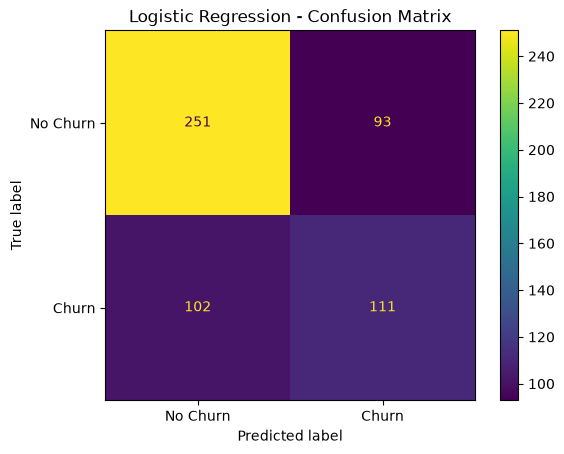

Accuracy: 0.6499
Precision: 0.5441
Recall: 0.5211
F1-score: 0.5324


In [43]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

### Random Forest Classifier

در این مرحله از الگوریتم Random Forest برای پیش‌بینی ریزش مشتریان استفاده می‌کنیم.

Random Forest از مجموعه‌ای از درخت‌های تصمیم تشکیل شده است. هر درخت با بررسی ویژگی‌های مشتریان، یک پیش‌بینی انجام می‌دهد و در نهایت خروجی درخت‌ها با یکدیگر ترکیب می‌شود.

این الگوریتم می‌تواند روابط غیرخطی و الگوهای پیچیده‌تر بین ویژگی‌های مشتریان را شناسایی کند.

در این مدل از همان داده‌های Train و Test استفاده می‌کنیم تا مقایسه با Logistic Regression منصفانه باشد.


In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


### Random Forest Prediction

در این مرحله از مدل آموزش‌دیده Random Forest برای پیش‌بینی وضعیت مشتریان در مجموعه Test استفاده می‌کنیم.

خروجی مدل شامل دو کلاس است:

* `0`: مشتری ریزش نکرده است.
* `1`: مشتری ریزش کرده است.

این پیش‌بینی‌ها در مراحل بعد برای ارزیابی عملکرد مدل و مقایسه آن با Logistic Regression استفاده خواهند شد.


In [45]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf[:20])

Random Forest Predictions:
[1 0 1 1 0 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0]


### Random Forest – Churn Probability

در این مرحله احتمال ریزش هر مشتری را با استفاده از مدل Random Forest محاسبه می‌کنیم.

تابع `predict_proba()` احتمال تعلق هر مشتری به کلاس‌های مختلف را برمی‌گرداند. از آنجا که هدف ما شناسایی مشتریان ریزش‌کرده است، احتمال مربوط به کلاس 1 را استخراج می‌کنیم.

این احتمال در مرحله بعد برای رتبه‌بندی مشتریان و انتخاب ۱۰۰ مشتری پرریسک استفاده خواهد شد.


In [46]:
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Churn Probabilities:")
print(y_proba_rf[:20])

Random Forest Churn Probabilities:
[0.87333333 0.45       0.76       0.55333333 0.36666667 0.8
 0.27       0.36333333 0.48       0.48333333 0.51666667 0.56333333
 0.06       0.17666667 0.39666667 0.18333333 0.22333333 0.68333333
 0.12       0.33      ]


### Random Forest – Customer Ranking

در این مرحله مشتریان را بر اساس احتمال ریزش پیش‌بینی‌شده توسط مدل Random Forest، از بیشترین به کمترین مرتب می‌کنیم.

سپس ۱۰۰ مشتری اول را انتخاب کرده و معیار Precision@100 را محاسبه می‌کنیم.

این معیار مشخص می‌کند چه تعداد از مشتریان انتخاب‌شده واقعاً در دوره آینده ریزش کرده‌اند.

نتیجه به‌دست‌آمده با روش‌های RFM و Logistic Regression مقایسه خواهد شد.


In [47]:
rf_results_test = pd.DataFrame({
    "CustomerID": ids_test,
    "Churn": y_test,
    "Predicted_Churn": y_pred_rf,
    "Churn_Probability": y_proba_rf
}, index=X_test.index)

rf_results_test = (
    rf_results_test
    .sort_values("Churn_Probability", ascending=False)
    .reset_index(drop=True)
)

top_100_rf = rf_results_test.head(k_test)

actual_churned_rf = (top_100_rf["Churn"] == 1).sum()

precision_at_100_rf = actual_churned_rf / k_test

print("Top 100 Selected Customers:", len(top_100_rf))
print("Actual Churned Customers:", actual_churned_rf)
print("Random Forest Precision@100:", round(precision_at_100_rf, 4))
print(
    "Random Forest Precision@100 (%):",
    round(precision_at_100_rf * 100, 2), "%"
)

display(top_100_rf.head(10))

Top 100 Selected Customers: 100
Actual Churned Customers: 54
Random Forest Precision@100: 0.54
Random Forest Precision@100 (%): 54.0 %


,CustomerID,Churn,Predicted_Churn,Churn_Probability
0,14059,1,1,0.966667
1,16036,0,1,0.966667
2,16093,1,1,0.963333
3,12639,1,1,0.963333
4,15584,0,1,0.916667
5,13072,1,1,0.896667
6,14326,1,1,0.896667
7,17542,1,1,0.886667
8,14699,1,1,0.873333
9,17048,1,1,0.860000


### Comparison of Classification Models

در این مرحله عملکرد دو الگوریتم Logistic Regression و Random Forest را با روش پایه RFM و انتخاب تصادفی مقایسه می‌کنیم.

معیار اصلی انتخاب مدل، Precision@100 است؛ زیرا هدف اصلی کسب‌وکار شناسایی بیشترین تعداد مشتریان در معرض ریزش با بودجه محدود تماس است.

مدلی که Precision@100 بالاتری داشته باشد، در این آزمایش توانسته تعداد بیشتری از مشتریان واقعاً ریزش‌کرده را در میان ۱۰۰ انتخاب اول شناسایی کند.


In [48]:
comparison_df = pd.DataFrame({
    "Method": [
        "Random Selection",
        "RFM Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Precision@100": [
        random_precision_at_100,
        precision_at_100,
        precision_at_100_logistic,
        precision_at_100_rf
    ]
})

comparison_df["Precision@100 (%)"] = (
    comparison_df["Precision@100"] * 100
).round(2)

comparison_df["Lift vs Random"] = (
    comparison_df["Precision@100"] / random_precision_at_100
).round(2)

display(comparison_df)

,Method,Precision@100,Precision@100 (%),Lift vs Random
0,Random Selection,0.382406,38.24,1.00
1,RFM Baseline,0.520000,52.00,1.36
2,Logistic Regression,0.550000,55.00,1.44
3,Random Forest,0.540000,54.00,1.41


### Random Forest – Model Evaluation

در این مرحله عملکرد مدل Random Forest را با استفاده از Confusion Matrix و معیارهای ارزیابی طبقه‌بندی بررسی می‌کنیم.

معیارهای مورد استفاده عبارت‌اند از:

* Accuracy
* Precision
* Recall
* F1-score

نتایج این مرحله با نتایج Logistic Regression مقایسه می‌شوند تا نقاط قوت و ضعف هر الگوریتم مشخص شود.


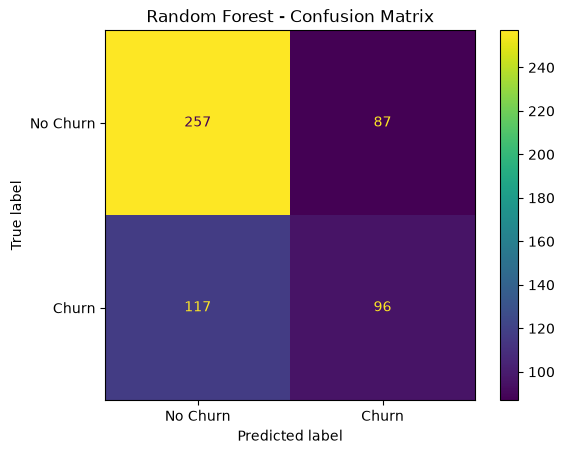

Accuracy: 0.6338
Precision: 0.5246
Recall: 0.4507
F1-score: 0.4848


In [49]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
)

disp_rf.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Accuracy:", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall:", round(recall_rf, 4))
print("F1-score:", round(f1_rf, 4))

### Classification Models Comparison

در این مرحله عملکرد دو الگوریتم Logistic Regression و Random Forest را با استفاده از معیارهای مختلف ارزیابی مقایسه می‌کنیم.

معیارهای مورد بررسی شامل Accuracy، Precision، Recall، F1-score و Precision@100 هستند.

هدف از این مقایسه، شناسایی الگوریتمی است که بتواند مشتریان در معرض ریزش را با دقت بیشتری شناسایی کند.

با توجه به محدودیت بودجه تماس با مشتریان، Precision@100 معیار اصلی تصمیم‌گیری کسب‌وکار خواهد بود.


In [50]:
classification_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, accuracy_rf],
    "Precision": [precision, precision_rf],
    "Recall": [recall, recall_rf],
    "F1-score": [f1, f1_rf],
    "Precision@100": [
        precision_at_100_logistic,
        precision_at_100_rf
    ]
})

display(
    classification_comparison
    .set_index("Model")
    .round(4)
)

,Accuracy,Precision,Recall,F1-score,Precision@100
Model,,,,,
Logistic Regression,0.6499,0.5441,0.5211,0.5324,0.55
Random Forest,0.6338,0.5246,0.4507,0.4848,0.54


### Feature Importance – Logistic Regression

در این مرحله اهمیت ویژگی‌های استفاده‌شده در مدل Logistic Regression را بررسی می‌کنیم.

مدل Logistic Regression برای هر ویژگی یک ضریب (Coefficient) یاد می‌گیرد. این ضرایب نشان می‌دهند هر ویژگی چه رابطه‌ای با احتمال پیش‌بینی‌شده ریزش مشتری دارد.

از آنجا که ویژگی‌های ورودی استانداردسازی شده‌اند، می‌توانیم قدر مطلق ضرایب را برای مقایسه اهمیت نسبی آن‌ها بررسی کنیم.

همچنین علامت ضریب مشخص می‌کند رابطه ویژگی با احتمال ریزش مثبت است یا منفی.


In [51]:
coefficients = logistic_model.coef_[0]

feature_importance_lr = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

feature_importance_lr = feature_importance_lr.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_lr)

,Feature,Coefficient,Importance
1,Frequency,-0.683920,0.683920
3,UniqueProducts,-0.288968,0.288968
0,Recency,0.164179,0.164179
2,Monetary,-0.116643,0.116643
4,TenureDays,-0.091642,0.091642


### Logistic Regression Coefficients Visualization

در این مرحله ضرایب مدل Logistic Regression را به‌صورت نمودار نمایش می‌دهیم.

مقادیر مثبت نشان‌دهنده رابطه مثبت ویژگی با احتمال پیش‌بینی‌شده ریزش و مقادیر منفی نشان‌دهنده رابطه معکوس هستند.

قدر مطلق ضرایب نیز برای مقایسه اهمیت نسبی ویژگی‌ها استفاده می‌شود.


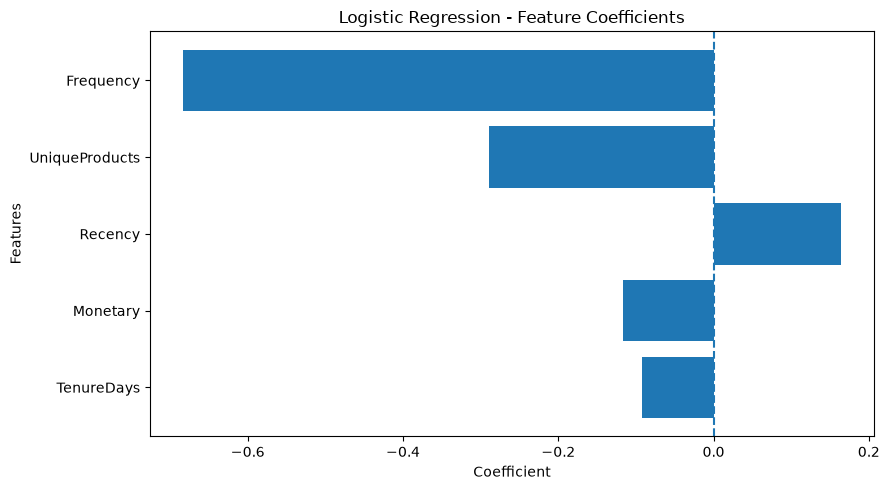

In [52]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance_lr["Feature"],
    feature_importance_lr["Coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Coefficient")
plt.ylabel("Features")
plt.title("Logistic Regression - Feature Coefficients")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Random Forest – Feature Importance

در این مرحله اهمیت ویژگی‌ها را در مدل Random Forest بررسی می‌کنیم.

Random Forest از چندین درخت تصمیم تشکیل شده است. هر درخت با استفاده از ویژگی‌های مختلف، مشتریان را تقسیم‌بندی می‌کند.

این الگوریتم با استفاده از معیار Feature Importance مشخص می‌کند هر ویژگی تا چه اندازه در تقسیم‌بندی‌های درخت‌ها نقش داشته است.

هدف، شناسایی مهم‌ترین ویژگی‌های رفتاری مشتریان در پیش‌بینی ریزش است.


In [53]:
rf_importances = rf_model.feature_importances_

feature_importance_rf = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_importances
})

feature_importance_rf = feature_importance_rf.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_rf)

,Feature,Importance
2,Monetary,0.316309
0,Recency,0.244831
3,UniqueProducts,0.215635
4,TenureDays,0.151061
1,Frequency,0.072163


### Feature Importance Comparison

در این مرحله اهمیت ویژگی‌ها را در دو الگوریتم Logistic Regression و Random Forest مقایسه می‌کنیم.

هدف این مقایسه بررسی تفاوت دیدگاه دو الگوریتم درباره ویژگی‌های مؤثر در پیش‌بینی ریزش مشتریان است.

در Logistic Regression از قدر مطلق ضرایب و در Random Forest از اهمیت ویژگی‌ها بر اساس تقسیم‌بندی درخت‌ها استفاده می‌کنیم.

برای نمایش مقایسه‌ای، مقادیر قدر مطلق ضرایب Logistic Regression را به مجموع یک نرمال می‌کنیم. این کار فقط برای مقایسه سهم نسبی ویژگی‌ها در نمودار است و به معنای یکسان بودن دو معیار نیست.


In [54]:
lr_importance = feature_importance_lr[
    ["Feature", "Importance"]
].copy()

lr_importance = lr_importance.rename(
    columns={"Importance": "LR_Importance"}
)

lr_importance["LR_Importance"] = (
    lr_importance["LR_Importance"] /
    lr_importance["LR_Importance"].sum()
)

rf_importance = feature_importance_rf[
    ["Feature", "Importance"]
].copy()

rf_importance = rf_importance.rename(
    columns={"Importance": "RF_Importance"}
)

feature_comparison = lr_importance.merge(
    rf_importance,
    on="Feature"
)

feature_comparison["LR_Rank"] = (
    feature_comparison["LR_Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

feature_comparison["RF_Rank"] = (
    feature_comparison["RF_Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

feature_comparison = feature_comparison.sort_values(
    "LR_Importance",
    ascending=False
)

display(feature_comparison.round(4))

,Feature,LR_Importance,RF_Importance,LR_Rank,RF_Rank
0,Frequency,0.5084,0.0722,1,5
1,UniqueProducts,0.2148,0.2156,2,3
2,Recency,0.1220,0.2448,3,2
3,Monetary,0.0867,0.3163,4,1
4,TenureDays,0.0681,0.1511,5,4


### Final Model Selection

در این مرحله عملکرد الگوریتم‌های Logistic Regression و Random Forest را بررسی کرده و مدل نهایی را انتخاب می‌کنیم.

با توجه به اینکه هدف اصلی پروژه شناسایی بیشترین تعداد مشتریان در معرض ریزش با محدودیت بودجه تماس است، معیار Precision@100 به‌عنوان معیار اصلی انتخاب مدل در نظر گرفته می‌شود.

نتایج ارزیابی نشان می‌دهد Logistic Regression با مقدار Precision@100 برابر 55% عملکرد بهتری نسبت به Random Forest با مقدار 54% داشته است.

همچنین Logistic Regression در معیارهای Accuracy، Precision، Recall و F1-score نیز عملکرد بهتری نشان داده است.

بنابراین Logistic Regression به‌عنوان مدل منتخب این آزمایش انتخاب می‌شود.


In [55]:

best_model_name = classification_comparison.loc[
    classification_comparison["Precision@100"].idxmax(),
    "Model"
]

model_candidates = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

best_model = model_candidates[best_model_name]

print("Selected Model:", best_model_name)
print("Best Precision@100:", precision_at_100_logistic)

Selected Model: Logistic Regression
Best Precision@100: 0.55


### Final Model Training

در این مرحله پس از انتخاب الگوریتم برتر، مدل Logistic Regression را مجدداً با استفاده از تمام داده‌های موجود آموزش می‌دهیم.

در مراحل قبلی، ۸۰ درصد داده‌ها برای آموزش و ۲۰ درصد برای ارزیابی استفاده شدند. اکنون با توجه به انتخاب مدل نهایی، از کل داده‌های دارای برچسب برای آموزش نسخه نهایی استفاده می‌کنیم.

این مدل در مرحله بعد برای محاسبه احتمال ریزش و رتبه‌بندی مشتریان مورد استفاده قرار خواهد گرفت.


In [56]:
X_full = X_cls.copy()
y_full = y_cls.copy()

X_full_transformed = X_full.copy()

X_full_transformed[log_features] = np.log1p(
    X_full_transformed[log_features]
)

scaler_final = StandardScaler()

X_full_scaled_array = scaler_final.fit_transform(
    X_full_transformed
)

X_full_scaled = pd.DataFrame(
    X_full_scaled_array,
    columns=feature_columns,
    index=X_full.index
)

print("Full dataset shape:", X_full_scaled.shape)

Full dataset shape: (2783, 5)


In [57]:
logistic_model_final = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model_final.fit(
    X_full_scaled,
    y_full
)

print("Final Logistic Regression trained successfully!")

Final Logistic Regression trained successfully!


### Customer Churn Probability – Out-of-Fold Prediction

در این مرحله احتمال ریزش تمام مشتریان را با استفاده از روش Out-of-Fold Prediction محاسبه می‌کنیم.

داده‌ها به پنج بخش تقسیم می‌شوند. در هر مرحله، چهار بخش برای آموزش مدل و بخش باقی‌مانده برای پیش‌بینی استفاده می‌شود.

این فرآیند پنج بار تکرار می‌شود تا هر مشتری یک احتمال ریزش از مدلی دریافت کند که در آموزش خود آن مشتری را ندیده است.

در نهایت برای تمام مشتریان یک مقدار Churn Probability تولید می‌شود که در مرحله بعد برای رتبه‌بندی و انتخاب ۵۰۰ مشتری پرریسک استفاده خواهد شد.


In [58]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = pd.Series(
    index=X_cls.index,
    dtype=float,
    name="Churn_Probability"
)

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_cls, y_cls),
    start=1
):
    X_fold_train = X_cls.iloc[train_idx].copy()
    X_fold_valid = X_cls.iloc[valid_idx].copy()

    y_fold_train = y_cls.iloc[train_idx]

    X_fold_train[log_features] = np.log1p(
        X_fold_train[log_features]
    )

    X_fold_valid[log_features] = np.log1p(
        X_fold_valid[log_features]
    )

    scaler_fold = StandardScaler()

    X_fold_train_scaled = scaler_fold.fit_transform(
        X_fold_train
    )

    X_fold_valid_scaled = scaler_fold.transform(
        X_fold_valid
    )

    model_fold = LogisticRegression(
        random_state=42,
        max_iter=1000
    )

    model_fold.fit(
        X_fold_train_scaled,
        y_fold_train
    )

    fold_probabilities = model_fold.predict_proba(
        X_fold_valid_scaled
    )[:, 1]

    oof_probabilities.iloc[valid_idx] = fold_probabilities

    print(f"Fold {fold} completed")

print("\nAll customers scored:",
      oof_probabilities.notna().all())

print("Total customers:",
      oof_probabilities.notna().sum())

display(oof_probabilities.head(10).to_frame())

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

All customers scored: True
Total customers: 2783


,Churn_Probability
0,0.185747
1,0.676942
2,0.566058
3,0.697400
4,0.445089
5,0.574607
6,0.560238
7,0.544685
8,0.467661
9,0.248158


### Customer Ranking and Top 500 Selection

در این مرحله مشتریان را بر اساس احتمال ریزش پیش‌بینی‌شده، از بیشترین به کمترین مرتب می‌کنیم.

با توجه به محدودیت بودجه کسب‌وکار، امکان تماس با حداکثر ۵۰۰ مشتری وجود دارد؛ بنابراین ۵۰۰ مشتری با بالاترین احتمال ریزش انتخاب می‌شوند.

برای هر مشتری، رتبه ریسک (Risk Rank) تعیین می‌شود تا اولویت تماس با مشتریان مشخص باشد.

همچنین با استفاده از برچسب واقعی ریزش، عملکرد این انتخاب را با معیار Precision@500 ارزیابی می‌کنیم.


In [59]:
ranked_customers = pd.DataFrame({
    "CustomerID": customer_ids.loc[oof_probabilities.index],
    "Churn": y_cls.loc[oof_probabilities.index],
    "Churn_Probability": oof_probabilities
})

ranked_customers = ranked_customers.sort_values(
    by="Churn_Probability",
    ascending=False
).reset_index(drop=True)

ranked_customers.insert(
    0,
    "Risk_Rank",
    np.arange(1, len(ranked_customers) + 1)
)

top_500_customers = ranked_customers.head(500).copy()

actual_churned_500 = (
    top_500_customers["Churn"] == 1
).sum()

precision_at_500 = actual_churned_500 / len(top_500_customers)

print("Total Customers:", len(ranked_customers))
print("Selected Customers:", len(top_500_customers))
print("Actual Churned Customers:", actual_churned_500)

print(
    "Out-of-Fold Precision@500:",
    round(precision_at_500, 4)
)

print(
    "Out-of-Fold Precision@500 (%):",
    round(precision_at_500 * 100, 2),
    "%"
)

display(top_500_customers.head(10))

Total Customers: 2783
Selected Customers: 500
Actual Churned Customers: 311
Out-of-Fold Precision@500: 0.622
Out-of-Fold Precision@500 (%): 62.2 %


,Risk_Rank,CustomerID,Churn,Churn_Probability
0,1,17816,0,0.845923
1,2,17763,1,0.806010
2,3,17956,1,0.799357
3,4,15863,0,0.787960
4,5,17080,0,0.770503
5,6,17580,1,0.769737
6,7,15759,1,0.768773
7,8,17102,1,0.767583
8,9,13261,1,0.766799
9,10,12547,1,0.766207


### Final Customer List – Export

در این مرحله فهرست ۵۰۰ مشتری با بالاترین احتمال ریزش را آماده و ذخیره می‌کنیم.

از آنجا که هدف این خروجی استفاده عملیاتی توسط تیم بازاریابی است، فقط اطلاعات موردنیاز برای اولویت‌بندی مشتریان را نگهداری می‌کنیم.

ستون‌های خروجی عبارت‌اند از:

* CustomerID: شناسه مشتری
* Risk_Rank: رتبه مشتری از نظر ریسک ریزش
* Churn_Probability: احتمال پیش‌بینی‌شده ریزش

ستون Churn از خروجی حذف می‌شود؛ زیرا در زمان استفاده واقعی از مدل، وضعیت ریزش آینده مشتریان هنوز مشخص نیست.


In [60]:
final_customer_list = top_500_customers[
    ["CustomerID", "Risk_Rank", "Churn_Probability"]
].copy()

assert len(final_customer_list) == 500
assert final_customer_list["CustomerID"].nunique() == 500
assert final_customer_list["Churn_Probability"].between(0, 1).all()

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "top_500_at_risk_customers.csv"

final_customer_list.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Final customer list saved successfully!")
print("File path:", output_path)
print("Total customers:", len(final_customer_list))

display(final_customer_list.head(10))

Final customer list saved successfully!
File path: outputs\top_500_at_risk_customers.csv
Total customers: 500


,CustomerID,Risk_Rank,Churn_Probability
0,17816,1,0.845923
1,17763,2,0.806010
2,17956,3,0.799357
3,15863,4,0.787960
4,17080,5,0.770503
5,17580,6,0.769737
6,15759,7,0.768773
7,17102,8,0.767583
8,13261,9,0.766799
9,12547,10,0.766207
